# Credit Risk: dimensionality reduction analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cristhian731/Credit-Risk/blob/main/notebooks/credit_risk_dimensionality.ipynb)

This notebook studies the data behind the credit risk models and answers three questions:

1. **What does the data look like?** A short exploratory analysis (EDA).
2. **Can the 9 input features be reduced?** PCA and t-SNE, and an experiment that trains the champion on PCA components instead of the original features.
3. **What happens to the age bias if the model does not see `Age`?** The champion was found to flag young applicants far more often than older ones (see `subgroups.json`). Here we repeat the same cross-validation without `Age`.

Rules that keep the results comparable with the web app:

- The code of the app is reused (`ml/dataset.py`, `ml/pipelines.py`, `ml/train.py`), so the data, the split, the pipeline and the cross-validation are the same ones used to train the models.
- **Only the train split is used.** The test split is deleted right after the split, so nothing here can tune or select a model with it.
- The champion and its tuned hyperparameters come from `ml/artifacts/manifest.json`. The model in production is **not** changed by this notebook.
- Every random step uses the seed 42.

## 1. Setup

In **Google Colab** the next cell clones the repository and installs `requirements-notebook.txt` (the same package versions as the app, plus matplotlib and seaborn). If Colab asks you to restart the runtime after the installation, restart it and run the notebook again from the top.

Locally, run the notebook from the repository root with the project virtual environment (Python 3.12 or newer).

`BRANCH` is the branch that is cloned in Colab. It must contain `ml/dataset.py`, `ml/pipelines.py` and the trained artifacts (`ml/artifacts/`).

In [1]:
import os
import subprocess
import sys
import warnings

REPO_URL = "https://github.com/Cristhian731/Credit-Risk.git"
BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("Credit-Risk"):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL], check=True)
    os.chdir("Credit-Risk")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-notebook.txt"], check=True)
else:
    # Locally: move up to the repository root (the folder that contains ml/).
    while not os.path.isdir("ml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

assert sys.version_info >= (3, 12), "requirements-notebook.txt needs Python 3.12 or newer"
warnings.filterwarnings("ignore", category=FutureWarning)
print("Setup done. Running in Colab:", IN_COLAB)

Setup done. Running in Colab: False


In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")  # figures are saved to files and displayed from them
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from ml import dataset
from ml.evaluate import AGE_BINS, AGE_LABELS, THRESHOLD
from ml.features import ARTIFACTS_DIR, DEFAULT_FEATURE_SET, FEATURE_SETS, MANIFEST_FILENAME, METRICS_FILENAME
from ml.pipelines import RANDOM_STATE, SEARCH_SPACES, build_pipeline
from ml.schemas import load_json, validate_dimensionality_report
from ml.train import CV_FOLDS, SCORING

sns.set_theme(style="whitegrid")
FIG_DIR = os.path.join("static", "img", "methodology")
os.makedirs(FIG_DIR, exist_ok=True)
FIGURES = []


def show(fig, name):
    """Save a figure under static/img/methodology/ (no tool metadata) and display the saved file."""
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=110, bbox_inches="tight", metadata={"Software": None})
    plt.close(fig)
    display(Image(filename=path))
    FIGURES.append(f"methodology/{name}")

## 2. Data

The dataset is the **Loan Default Prediction Dataset** (255,347 rows, 18 columns). It is not stored in the repository.

- **Kaggle:** search for "Loan Default Prediction Dataset" on kaggle.com, download `Loan_default.csv` and keep the file as it is (the app checks its SHA-256; see `ml/data/README.md`).
- **Colab:** if the file is not found, the next cell opens an upload dialog; choose `Loan_default.csv`.
- **Locally:** put the file in `ml/data/raw/`.

`dataset.load` checks the columns and the target, and warns if the SHA-256 differs from the expected one. Then the data is cleaned and split 80/20 (stratified, seed 42) exactly as in `python -m ml.train`. **The test split is deleted immediately.**

In [3]:
DATA_PATH = dataset.DEFAULT_DATA_PATH
if not os.path.exists(DATA_PATH):
    if IN_COLAB:
        from google.colab import files

        os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
        uploaded = files.upload()  # choose Loan_default.csv
        os.replace(next(iter(uploaded)), DATA_PATH)
    else:
        raise FileNotFoundError("Put Loan_default.csv in ml/data/raw/ (see ml/data/README.md).")

raw = dataset.load(DATA_PATH)
cleaned = dataset.clean(raw)
X_train, X_test, y_train, y_test = dataset.split(cleaned)
del X_test, y_test  # the test split is never used in this notebook

print("Rows:", len(raw), "| train rows:", len(X_train))
print("SHA-256 matches the expected file:", raw.attrs["sha256"] == dataset.EXPECTED_SHA256)
print(f"Default rate in train: {y_train.mean():.2%}")

Rows: 255347 | train rows: 204277
SHA-256 matches the expected file: True
Default rate in train: 11.61%


## 3. The champion and its features

The models use the 9 columns of the feature set `v2-loan-default` (8 numeric columns and `EmploymentType`). The cell below reads the champion and its tuned hyperparameters from the trained artifacts, and builds the same pipeline with `build_pipeline`. Every experiment reuses it, so the only thing that changes between a baseline and a variant is what the experiment says it changes.

In [4]:
manifest = load_json(os.path.join(ARTIFACTS_DIR, MANIFEST_FILENAME))
champion = manifest["champion"]
champion_metrics = load_json(os.path.join(ARTIFACTS_DIR, champion, METRICS_FILENAME))

FEATURES = FEATURE_SETS[DEFAULT_FEATURE_SET]
NUMERIC = [c for c in FEATURES["columns"] if c not in FEATURES["categorical"]]
scale_pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())
tuned = {key.split("__", 1)[1]: champion_metrics["params"][key.split("__", 1)[1]] for key in SEARCH_SPACES[champion]}


def make_pipeline(feature_set=DEFAULT_FEATURE_SET):
    """The champion pipeline with its tuned hyperparameters."""
    pipeline = build_pipeline(champion, feature_set=feature_set, scale_pos_weight=scale_pos_weight)
    return pipeline.set_params(**{f"classifier__{name}": value for name, value in tuned.items()})


print("Champion:", champion, "| tuned hyperparameters:", tuned)
print("Features:", list(FEATURES["columns"]))

Champion: logistic_regression | tuned hyperparameters: {'C': 0.01}
Features: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'LoanTerm', 'DTIRatio', 'EmploymentType']


## 4. Exploratory data analysis

**Target.** The classes are imbalanced: far fewer applicants default than repay. That is why the models use class weights, and why recall of class 1 matters as much as ROC AUC.

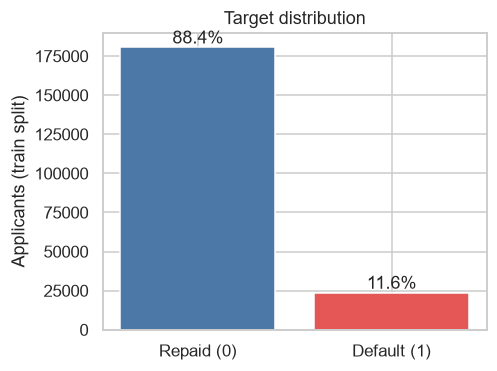

In [5]:
counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.5))
bars = ax.bar(["Repaid (0)", "Default (1)"], counts.values, color=["#4c78a8", "#e45756"])
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value / counts.sum():.1%}", ha="center", va="bottom")
ax.set_ylabel("Applicants (train split)")
ax.set_title("Target distribution")
show(fig, "eda_target.png")

**Main variables.** For each numeric feature, applicants are grouped in deciles (or by value when there are few distinct values) and the plot shows the share of defaults in each group. A line that moves away from the dashed base rate means the variable carries signal.

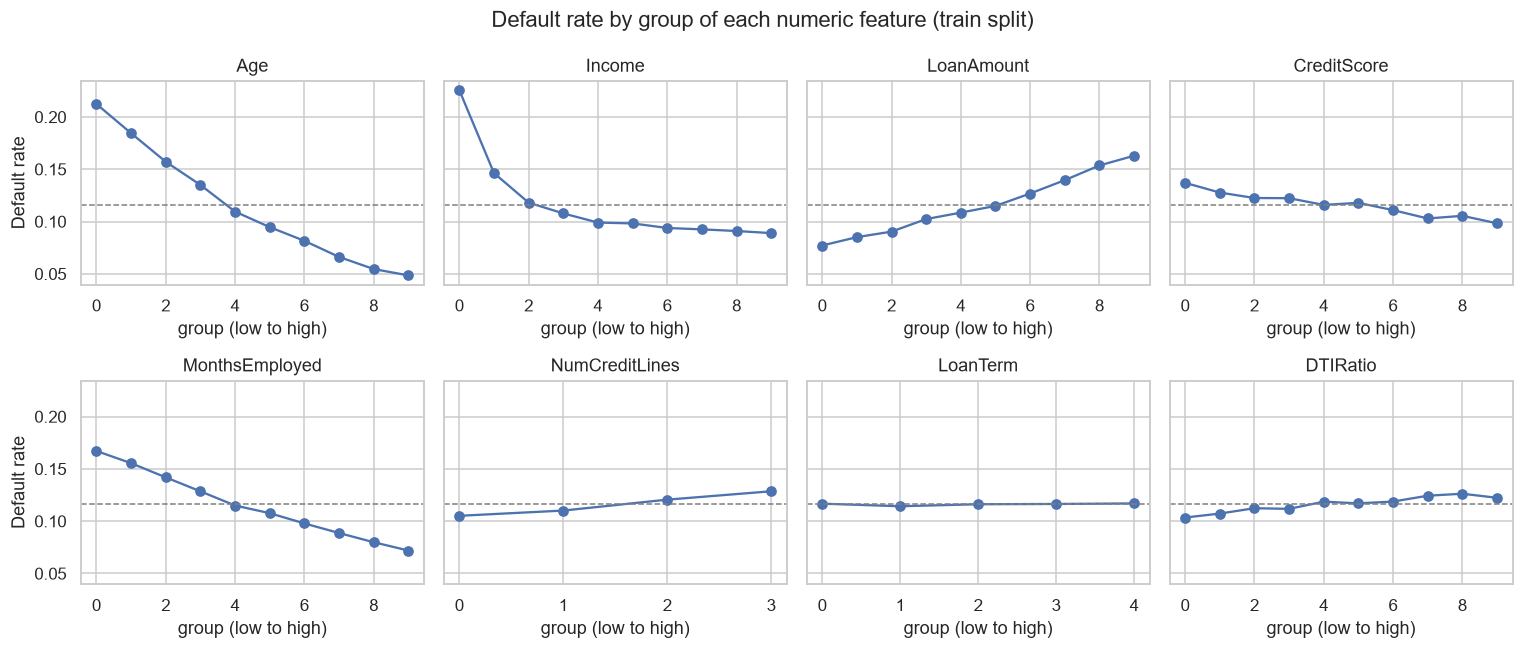

Default rate by EmploymentType:
EmploymentType
Full-time        0.0946
Part-time        0.1191
Self-employed    0.1153
Unemployed       0.1355


In [6]:
train_df = X_train.assign(Default=y_train)
base_rate = float(y_train.mean())

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharey=True)
for ax, column in zip(axes.ravel(), NUMERIC):
    groups = pd.qcut(train_df[column], q=10, duplicates="drop") if train_df[column].nunique() > 10 else train_df[column]
    rate = train_df.groupby(groups, observed=True)["Default"].mean()
    ax.plot(range(len(rate)), rate.values, marker="o")
    ax.axhline(base_rate, color="grey", linestyle="--", linewidth=1)
    ax.set_title(column)
    ax.set_xlabel("group (low to high)")
axes[0, 0].set_ylabel("Default rate")
axes[1, 0].set_ylabel("Default rate")
fig.suptitle("Default rate by group of each numeric feature (train split)")
fig.tight_layout()
show(fig, "eda_default_rate_by_feature.png")

print("Default rate by EmploymentType:")
print(train_df.groupby("EmploymentType")["Default"].mean().round(4).to_string())

**Correlations.** Pearson correlations between the numeric features and the target. If the features were strongly correlated with each other, a few principal components would summarize them; the heatmap tells us what to expect from PCA.

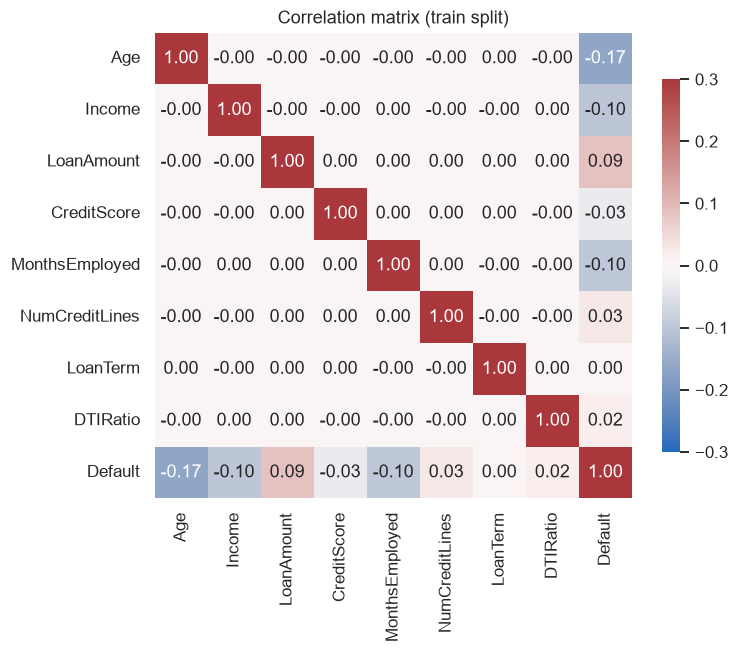

Correlation with Default:
Age              -0.166
Income           -0.099
MonthsEmployed   -0.096
LoanAmount        0.086
CreditScore      -0.035
NumCreditLines    0.028
DTIRatio          0.021
LoanTerm          0.001

Largest absolute correlation between two features: 0.004
Correlation Age vs MonthsEmployed: -0.001


In [7]:
corr = train_df[NUMERIC + ["Default"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.3, vmax=0.3, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix (train split)")
show(fig, "eda_correlations.png")

with_target = corr["Default"].drop("Default")
print("Correlation with Default:")
print(with_target.reindex(with_target.abs().sort_values(ascending=False).index).round(3).to_string())

features_only = corr.loc[NUMERIC, NUMERIC].where(~np.eye(len(NUMERIC), dtype=bool))
max_feature_corr = float(features_only.abs().max().max())
print(f"\nLargest absolute correlation between two features: {max_feature_corr:.3f}")
age_months_corr = float(corr.loc["Age", "MonthsEmployed"])
print(f"Correlation Age vs MonthsEmployed: {age_months_corr:.3f}")

## 5. PCA

Principal Component Analysis rotates the data into new axes (components) ordered by the variance they explain.

1. The pipeline's own preprocessing is applied (median imputation, scaling of the numeric columns and one-hot encoding of `EmploymentType`, which gives 12 columns).
2. Every column is **standardized** (mean 0, variance 1), because PCA is driven by variance and would otherwise be dominated by `Income` and `LoanAmount`, which are in the tens of thousands.
3. PCA is fitted on the train split and the scree plot shows how much variance each component keeps.

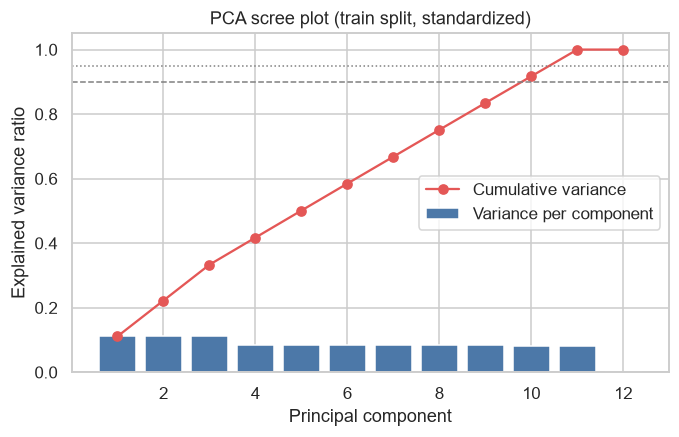

12 columns after preprocessing: ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'LoanTerm', 'DTIRatio', 'EmploymentType_Full-time', 'EmploymentType_Part-time', 'EmploymentType_Self-employed', 'EmploymentType_Unemployed']
First component: 11.1% of the variance
Components for 90% of the variance: 10 | for 95%: 11


In [8]:
preprocessor = clone(make_pipeline().named_steps["preprocessing"]).fit(X_train)
Z = preprocessor.transform(X_train)
Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
feature_names = [name.split("__", 1)[-1] for name in preprocessor.get_feature_names_out()]
Zs = StandardScaler().fit_transform(Z)

pca = PCA(random_state=RANDOM_STATE).fit(Zs)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
k90 = int(np.searchsorted(cumulative, 0.90) + 1)
k95 = int(np.searchsorted(cumulative, 0.95) + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(explained) + 1), explained, color="#4c78a8", label="Variance per component")
ax.plot(range(1, len(explained) + 1), cumulative, marker="o", color="#e45756", label="Cumulative variance")
ax.axhline(0.90, color="grey", linestyle="--", linewidth=1)
ax.axhline(0.95, color="grey", linestyle=":", linewidth=1)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA scree plot (train split, standardized)")
ax.legend(loc="center right")
show(fig, "pca_scree.png")

print(f"{len(feature_names)} columns after preprocessing: {feature_names}")
print(f"First component: {explained[0]:.1%} of the variance")
print(f"Components for 90% of the variance: {k90} | for 95%: {k95}")

**2D projection.** Each point is an applicant (a random sample of 20,000 from the train split) placed by its first two components and colored by the real outcome. If defaulters and repayers formed separate groups, the colors would split in this plane.

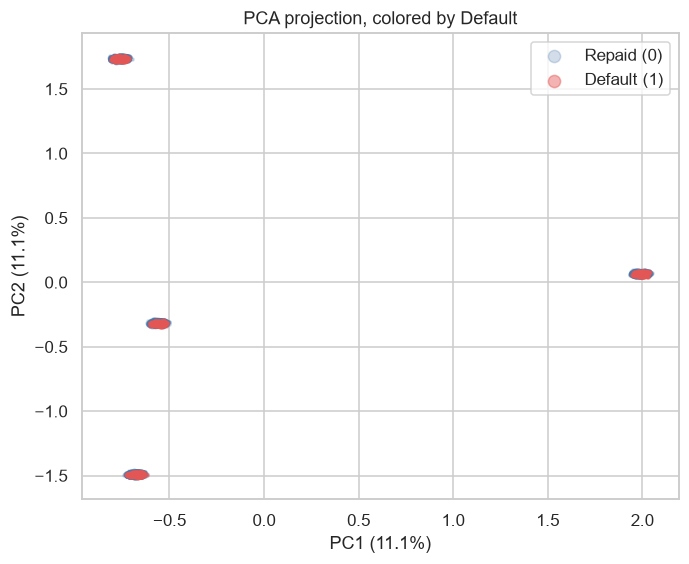

Loadings of the first two components:
                                PC1    PC2
Age                          -0.016  0.001
Income                       -0.006  0.001
LoanAmount                   -0.007 -0.006
CreditScore                  -0.003  0.004
MonthsEmployed                0.006  0.003
NumCreditLines                0.001  0.003
LoanTerm                      0.003 -0.003
DTIRatio                      0.002 -0.003
EmploymentType_Full-time     -0.242 -0.137
EmploymentType_Part-time      0.864  0.030
EmploymentType_Self-employed -0.330  0.752
EmploymentType_Unemployed    -0.294 -0.645


In [9]:
rng = np.random.default_rng(RANDOM_STATE)
sample = rng.choice(len(Zs), size=min(20000, len(Zs)), replace=False)
scores = pca.transform(Zs[sample])
labels = y_train.to_numpy()[sample]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(scores[labels == 0, 0], scores[labels == 0, 1], s=4, alpha=0.25, color="#4c78a8", label="Repaid (0)")
ax.scatter(scores[labels == 1, 0], scores[labels == 1, 1], s=4, alpha=0.45, color="#e45756", label="Default (1)")
ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
ax.set_title("PCA projection, colored by Default")
ax.legend(markerscale=4)
show(fig, "pca_projection.png")

loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=["PC1", "PC2"]).round(3)
print("Loadings of the first two components:")
print(loadings.to_string())

## 6. t-SNE

t-SNE is a non-linear technique that keeps close neighbours close in 2D. It is slow, so it is run on a **stratified sample of 5,000 applicants** of the train split (same default rate as the full data) with a fixed seed. t-SNE is only for looking at the data: distances between clusters and cluster sizes in the plot should not be over-interpreted, and it is not used to train anything.

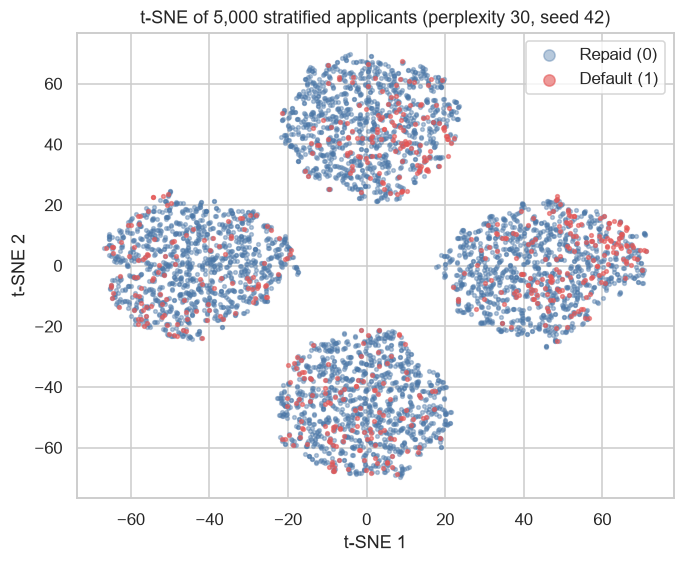

t-SNE KL divergence: 1.972


In [10]:
TSNE_ROWS = 5000
TSNE_PERPLEXITY = 30
sample_idx, _ = train_test_split(
    np.arange(len(Zs)), train_size=TSNE_ROWS, stratify=y_train, random_state=RANDOM_STATE
)
tsne = TSNE(
    n_components=2, perplexity=TSNE_PERPLEXITY, init="pca", learning_rate="auto", random_state=RANDOM_STATE
)
embedding = tsne.fit_transform(Zs[sample_idx])
tsne_labels = y_train.to_numpy()[sample_idx]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(embedding[tsne_labels == 0, 0], embedding[tsne_labels == 0, 1], s=6, alpha=0.4, color="#4c78a8", label="Repaid (0)")
ax.scatter(embedding[tsne_labels == 1, 0], embedding[tsne_labels == 1, 1], s=6, alpha=0.6, color="#e45756", label="Default (1)")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title(f"t-SNE of {TSNE_ROWS:,} stratified applicants (perplexity {TSNE_PERPLEXITY}, seed {RANDOM_STATE})")
ax.legend(markerscale=3)
show(fig, "tsne_projection.png")
print(f"t-SNE KL divergence: {tsne.kl_divergence_:.3f}")

## 7. Experiment 1: the champion on PCA components

Question: does the champion lose accuracy if, instead of the original features, it only sees the first *k* principal components?

- **Baseline:** the champion pipeline with the original features.
- **Variants:** the same preprocessing, then standardization, then `PCA(k)`, then the same classifier with the same hyperparameters.
- **Evaluation:** the 5-fold stratified cross-validation on the train split used by `ml.train`. PCA is fitted *inside* each fold, so the held-out fold never influences the components.
- Metrics: mean and standard deviation of ROC AUC and of recall of class 1 (threshold 0.5).

In [11]:
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORES = {name: SCORING[name] for name in ("roc_auc", "recall")}


def cv_summary(estimator):
    result = cross_validate(estimator, X_train, y_train, cv=cv, scoring=SCORES, n_jobs=-1)
    return {
        name: [round(float(result[f"test_{name}"].mean()), 4), round(float(result[f"test_{name}"].std()), 4)]
        for name in SCORES
    }


base = make_pipeline()
baseline = cv_summary(base)
print("Baseline (original features):", baseline)

component_counts = (2, 3, 4, 6, 8, 10, len(feature_names))
pca_variants = []
for k in component_counts:
    pipeline = Pipeline([
        ("preprocessing", clone(base.named_steps["preprocessing"])),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=k, random_state=RANDOM_STATE)),
        ("classifier", clone(base.named_steps["classifier"])),
    ])
    summary = cv_summary(pipeline)
    pca_variants.append({
        "n_components": int(k),
        "explained_variance": round(float(cumulative[k - 1]), 4),
        "cv": summary,
        "delta_roc_auc": round(summary["roc_auc"][0] - baseline["roc_auc"][0], 4),
        "delta_recall": round(summary["recall"][0] - baseline["recall"][0], 4),
    })

table = pd.DataFrame([
    {
        "components": v["n_components"],
        "variance kept": f"{v['explained_variance']:.1%}",
        "CV ROC AUC": f"{v['cv']['roc_auc'][0]:.4f} +/- {v['cv']['roc_auc'][1]:.4f}",
        "delta AUC": f"{v['delta_roc_auc']:+.4f}",
        "CV recall": f"{v['cv']['recall'][0]:.4f} +/- {v['cv']['recall'][1]:.4f}",
        "delta recall": f"{v['delta_recall']:+.4f}",
    }
    for v in pca_variants
])
print(table.to_string(index=False))

Baseline (original features): {'roc_auc': [0.7111, 0.0036], 'recall': [0.6635, 0.0052]}


 components variance kept        CV ROC AUC delta AUC         CV recall delta recall
          2         22.2% 0.5319 +/- 0.0128   -0.1792 0.5714 +/- 0.0915      -0.0921
          3         33.3% 0.5500 +/- 0.0108   -0.1611 0.5497 +/- 0.0043      -0.1138
          4         41.7% 0.5967 +/- 0.0304   -0.1144 0.5930 +/- 0.0101      -0.0705
          6         58.5% 0.6249 +/- 0.0127   -0.0862 0.5920 +/- 0.0131      -0.0715
          8         75.1% 0.6655 +/- 0.0219   -0.0456 0.6222 +/- 0.0186      -0.0413
         10         91.7% 0.7064 +/- 0.0060   -0.0047 0.6602 +/- 0.0061      -0.0033
         12        100.0% 0.7111 +/- 0.0036   +0.0000 0.6636 +/- 0.0050      +0.0001


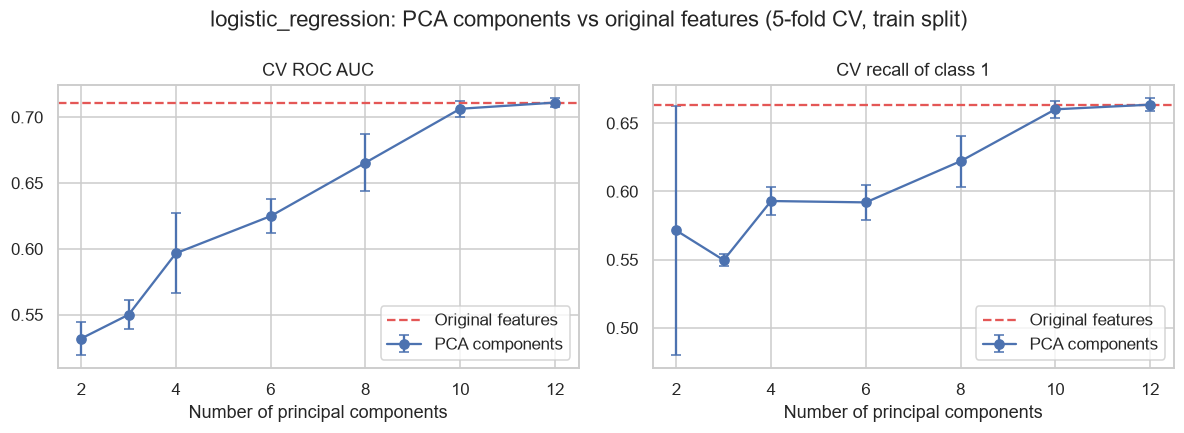

In [12]:
ks = [v["n_components"] for v in pca_variants]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(axes, ("roc_auc", "recall"), ("CV ROC AUC", "CV recall of class 1")):
    ax.errorbar(ks, [v["cv"][metric][0] for v in pca_variants], yerr=[v["cv"][metric][1] for v in pca_variants],
                marker="o", capsize=3, label="PCA components")
    ax.axhline(baseline[metric][0], color="#e45756", linestyle="--", label="Original features")
    ax.set_xlabel("Number of principal components")
    ax.set_title(title)
    ax.legend()
fig.suptitle(f"{champion}: PCA components vs original features (5-fold CV, train split)")
fig.tight_layout()
show(fig, "pca_experiment.png")

## 8. Experiment 2: feature selection "without Age"

The champion flags many more young applicants than older ones. `Age` is one of its most important inputs, and age is a sensitive attribute in credit decisions. This experiment removes `Age` from the feature set and keeps everything else equal: same champion, same tuned hyperparameters, same 5-fold cross-validation on the train split.

Besides the usual ROC AUC and recall, we compare **how often each age range is flagged as default** (predicted probability >= 0.5). The flagged rates come from out-of-fold predictions: each applicant is scored by a model that did not see them, so the numbers are honest estimates and the test split is not needed.

The feature set `v2-without-age` exists **only inside this notebook**. Nothing is saved to the model artifacts and the model in production does not change.

In [13]:
NO_AGE = "v2-without-age"
FEATURE_SETS[NO_AGE] = {
    "columns": tuple(c for c in FEATURES["columns"] if c != "Age"),
    "categorical": FEATURES["categorical"],
}

with_age = make_pipeline()
without_age = make_pipeline(NO_AGE)
cv_with, cv_without = cv_summary(with_age), cv_summary(without_age)

oof_with = cross_val_predict(with_age, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
oof_without = cross_val_predict(without_age, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
flag_with, flag_without = oof_with >= THRESHOLD, oof_without >= THRESHOLD

age_range = pd.cut(X_train["Age"], bins=list(AGE_BINS), labels=list(AGE_LABELS)).astype(str).to_numpy()
y_values = y_train.to_numpy()

by_age_range = {}
for label in AGE_LABELS:
    mask = age_range == label
    positives = mask & (y_values == 1)
    by_age_range[label] = {
        "rows": int(mask.sum()),
        "default_rate": round(float(y_values[mask].mean()), 4),
        "flagged_rate_with_age": round(float(flag_with[mask].mean()), 4),
        "flagged_rate_without_age": round(float(flag_without[mask].mean()), 4),
        "recall_with_age": round(float(flag_with[positives].mean()), 4),
        "recall_without_age": round(float(flag_without[positives].mean()), 4),
    }

youngest, oldest = by_age_range[AGE_LABELS[0]], by_age_range[AGE_LABELS[-1]]
ratio = {
    "with_age": round(youngest["flagged_rate_with_age"] / oldest["flagged_rate_with_age"], 2),
    "without_age": round(youngest["flagged_rate_without_age"] / oldest["flagged_rate_without_age"], 2),
}

print("Cross-validation on the train split (mean, std):")
print("  with Age   ", cv_with)
print("  without Age", cv_without)
print(f"Overall flagged rate: {flag_with.mean():.1%} with Age, {flag_without.mean():.1%} without Age")
print(pd.DataFrame(by_age_range).T.to_string())
print("Flagged-rate ratio youngest / oldest:", ratio)

Cross-validation on the train split (mean, std):
  with Age    {'roc_auc': [0.7111, 0.0036], 'recall': [0.6635, 0.0052]}
  without Age {'roc_auc': [0.6515, 0.0036], 'recall': [0.6117, 0.0068]}
Overall flagged rate: 39.1% with Age, 42.0% without Age
          rows  default_rate  flagged_rate_with_age  flagged_rate_without_age  recall_with_age  recall_without_age
18-24  27342.0        0.2103                 0.8508                    0.4172           0.9219              0.5814
25-34  39414.0        0.1645                 0.6884                    0.4192           0.8330              0.6080
35-44  39271.0        0.1196                 0.4451                    0.4204           0.6471              0.6224
45-54  39280.0        0.0881                 0.2199                    0.4221           0.4123              0.6250
55-69  58970.0        0.0565                 0.0569                    0.4190           0.1717              0.6424
Flagged-rate ratio youngest / oldest: {'with_age': 14.95, 'wi

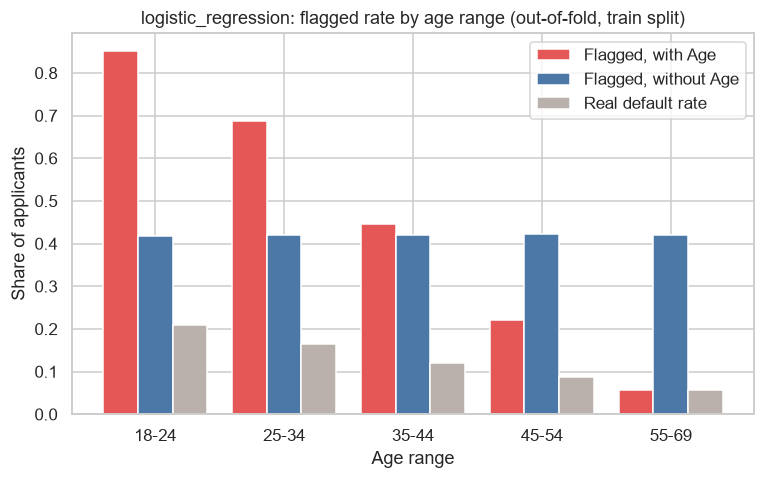

In [14]:
positions = np.arange(len(AGE_LABELS))
width = 0.27
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(positions - width, [by_age_range[l]["flagged_rate_with_age"] for l in AGE_LABELS], width, label="Flagged, with Age", color="#e45756")
ax.bar(positions, [by_age_range[l]["flagged_rate_without_age"] for l in AGE_LABELS], width, label="Flagged, without Age", color="#4c78a8")
ax.bar(positions + width, [by_age_range[l]["default_rate"] for l in AGE_LABELS], width, label="Real default rate", color="#bab0ac")
ax.set_xticks(positions)
ax.set_xticklabels(AGE_LABELS)
ax.set_xlabel("Age range")
ax.set_ylabel("Share of applicants")
ax.set_title(f"{champion}: flagged rate by age range (out-of-fold, train split)")
ax.legend()
show(fig, "age_experiment.png")

## 9. Interpretation

The text below is generated from the numbers above, so it always matches the results of the run.

In [15]:
n_cols = len(feature_names)
by_k = {v["n_components"]: v for v in pca_variants}
k_ref = min(k for k in by_k if by_k[k]["explained_variance"] >= 0.90)
small = by_k[component_counts[0]]
full = by_k[n_cols]
auc_drop_small = baseline["roc_auc"][0] - small["cv"]["roc_auc"][0]
auc_drop_ref = baseline["roc_auc"][0] - by_k[k_ref]["cv"]["roc_auc"][0]

middle = explained[3:-1]
flagged_without = [by_age_range[l]["flagged_rate_without_age"] for l in AGE_LABELS]
equalized = max(flagged_without) - min(flagged_without) < 0.05
old_extra = oldest["flagged_rate_without_age"] / max(oldest["flagged_rate_with_age"], 1e-9)

interpretation = [
    f"PCA: the features are almost uncorrelated (largest correlation between two features: {max_feature_corr:.2f}), "
    f"so PCA finds nothing to compress. The numeric part has no preferred direction: components 4 to {n_cols - 1} "
    f"keep between {middle.min():.1%} and {middle.max():.1%} of the variance each. The first three components "
    f"({explained[0]:.0%} each) only encode EmploymentType, because its standardized one-hot columns are correlated "
    f"with each other. {k90} of {n_cols} components are needed for 90% of the variance ({k95} for 95%).",
    f"Experiment 1: with {small['n_components']} components ({small['explained_variance']:.0%} of the variance) the CV "
    f"ROC AUC is {small['cv']['roc_auc'][0]:.4f} against {baseline['roc_auc'][0]:.4f} with the original features "
    f"(difference {-auc_drop_small:+.4f}). With {k_ref} components ({by_k[k_ref]['explained_variance']:.0%} of the "
    f"variance) it is {by_k[k_ref]['cv']['roc_auc'][0]:.4f} (difference {-auc_drop_ref:+.4f}). With all {n_cols} "
    f"components, which is only a rotation, the difference is {full['delta_roc_auc']:+.4f}. "
    + ("The variance ordering says nothing about predictive power, and every component dropped removes signal."
       if auc_drop_ref > 0.002 else
       "Dropping the low-variance components costs almost nothing."),
    "PCA keeps the directions with the most variance, not the ones that best separate defaulters. A model trained "
    "on a rotation of the features cannot add information that was not already there, and each component removed "
    "throws information away. Reducing dimensions also makes the model harder to explain, because a component "
    "mixes several features. For these reasons PCA is not used in the production model.",
    f"t-SNE (KL divergence {tsne.kl_divergence_:.2f}) draws four separated islands, one per EmploymentType (the "
    f"standardized one-hot columns dominate the distances). Inside each island defaulters are mixed with repayers, "
    f"and the PCA projection shows the same mixture. This agrees with a ROC AUC around {baseline['roc_auc'][0]:.2f}: "
    f"the signal is weak and spread over many features instead of concentrated in a few directions.",
    f"Experiment 2: without Age the CV ROC AUC goes from {cv_with['roc_auc'][0]:.4f} to {cv_without['roc_auc'][0]:.4f} "
    f"({cv_without['roc_auc'][0] - cv_with['roc_auc'][0]:+.4f}) and the CV recall from {cv_with['recall'][0]:.4f} to "
    f"{cv_without['recall'][0]:.4f} ({cv_without['recall'][0] - cv_with['recall'][0]:+.4f}).",
    f"Age bias: applicants aged {AGE_LABELS[0]} are flagged {youngest['flagged_rate_with_age']:.0%} of the time with "
    f"Age and {youngest['flagged_rate_without_age']:.0%} without it, while {AGE_LABELS[-1]} go from "
    f"{oldest['flagged_rate_with_age']:.0%} to {oldest['flagged_rate_without_age']:.0%}. The youngest-to-oldest "
    f"ratio of flagged rates changes from {ratio['with_age']} to {ratio['without_age']}. "
    + (f"Without Age the model flags about the same share of every age range, although the real default rate goes "
       f"from {youngest['default_rate']:.0%} to {oldest['default_rate']:.0%}. "
       if equalized else
       "Without Age the flagged rates of the age ranges are closer but still different. ")
    + f"The gap closes at a price: the oldest range is flagged {old_extra:.1f} times more often (more false alarms) "
    f"and the recall of the youngest range falls from {youngest['recall_with_age']:.0%} to "
    f"{youngest['recall_without_age']:.0%}. No other feature takes Age's place (correlation of Age with "
    f"MonthsEmployed: {age_months_corr:.2f}; the features are almost independent), so Age carries real signal "
    f"that is lost, not a bias that can be removed for free.",
    "Decision: the model in production is not changed. The without-Age variant is documented as a mitigation "
    "option to review with the domain expert, together with per-group thresholds and human review of rejections.",
]
display(Markdown("\n\n".join(f"- {line}" for line in interpretation)))

- PCA: the features are almost uncorrelated (largest correlation between two features: 0.00), so PCA finds nothing to compress. The numeric part has no preferred direction: components 4 to 11 keep between 8.3% and 8.4% of the variance each. The first three components (11% each) only encode EmploymentType, because its standardized one-hot columns are correlated with each other. 10 of 12 components are needed for 90% of the variance (11 for 95%).

- Experiment 1: with 2 components (22% of the variance) the CV ROC AUC is 0.5319 against 0.7111 with the original features (difference -0.1792). With 10 components (92% of the variance) it is 0.7064 (difference -0.0047). With all 12 components, which is only a rotation, the difference is +0.0000. The variance ordering says nothing about predictive power, and every component dropped removes signal.

- PCA keeps the directions with the most variance, not the ones that best separate defaulters. A model trained on a rotation of the features cannot add information that was not already there, and each component removed throws information away. Reducing dimensions also makes the model harder to explain, because a component mixes several features. For these reasons PCA is not used in the production model.

- t-SNE (KL divergence 1.97) draws four separated islands, one per EmploymentType (the standardized one-hot columns dominate the distances). Inside each island defaulters are mixed with repayers, and the PCA projection shows the same mixture. This agrees with a ROC AUC around 0.71: the signal is weak and spread over many features instead of concentrated in a few directions.

- Experiment 2: without Age the CV ROC AUC goes from 0.7111 to 0.6515 (-0.0596) and the CV recall from 0.6635 to 0.6117 (-0.0518).

- Age bias: applicants aged 18-24 are flagged 85% of the time with Age and 42% without it, while 55-69 go from 6% to 42%. The youngest-to-oldest ratio of flagged rates changes from 14.95 to 1.0. Without Age the model flags about the same share of every age range, although the real default rate goes from 21% to 6%. The gap closes at a price: the oldest range is flagged 7.4 times more often (more false alarms) and the recall of the youngest range falls from 92% to 58%. No other feature takes Age's place (correlation of Age with MonthsEmployed: -0.00; the features are almost independent), so Age carries real signal that is lost, not a bias that can be removed for free.

- Decision: the model in production is not changed. The without-Age variant is documented as a mitigation option to review with the domain expert, together with per-group thresholds and human review of rejections.

## 10. Export

The results are written to `ml/artifacts/dimensionality_report.json` (validated with `ml.schemas.validate_dimensionality_report`). The figures were already saved to `static/img/methodology/`, where the web app serves them.

In Colab the files are created inside the cloned repository; download them from the file browser if you want to commit them.

In [16]:
report = {
    "artifacts_version": manifest["version"],
    "champion": champion,
    "dataset": {"sha256": raw.attrs["sha256"], "train_rows": int(len(X_train))},
    "protocol": {
        "data": "Train split only (80% stratified, seed 42); the test split is deleted right after the split.",
        "cv_folds": CV_FOLDS,
        "random_state": RANDOM_STATE,
        "test_usage": "Not used. Flagged rates come from out-of-fold predictions on the train split.",
    },
    "pca": {
        "input_columns": feature_names,
        "explained_variance_ratio": [round(float(v), 4) for v in explained],
        "cumulative_variance": [round(float(v), 4) for v in cumulative],
        "components_for_90_percent": k90,
        "components_for_95_percent": k95,
    },
    "tsne": {
        "sample_rows": TSNE_ROWS,
        "perplexity": TSNE_PERPLEXITY,
        "random_state": RANDOM_STATE,
        "kl_divergence": round(float(tsne.kl_divergence_), 4),
    },
    "experiments": {
        "pca_components": {
            "baseline": {"n_features": len(FEATURES["columns"]), "cv": baseline},
            "variants": pca_variants,
        },
        "without_age": {
            "with_age": {"cv": cv_with, "flagged_rate": round(float(flag_with.mean()), 4)},
            "without_age": {"cv": cv_without, "flagged_rate": round(float(flag_without.mean()), 4)},
            "by_age_range": by_age_range,
            "flag_rate_ratio_youngest_to_oldest": ratio,
        },
    },
    "interpretation": interpretation,
    "figures": FIGURES,
}

errors = validate_dimensionality_report(report)
assert errors == [], errors

report_path = os.path.join(ARTIFACTS_DIR, "dimensionality_report.json")
with open(report_path, "w", encoding="utf-8", newline="\n") as fh:
    json.dump(report, fh, indent=2, ensure_ascii=False, allow_nan=False)
    fh.write("\n")
print("Saved ml/artifacts/dimensionality_report.json and", len(FIGURES), "figures in static/img/methodology/")

Saved ml/artifacts/dimensionality_report.json and 8 figures in static/img/methodology/
